### Model 1 - Geometric 
The first models will only use the geometric passing information:
- Passs start and end coordinates
- Pass distance
- Pass angle

We will train both a logisitc regressor and Gradient Booster on the same data and comapre their results.

In [1]:
# -------------------------------------------
# 1. Load the passing data
# -------------------------------------------
import pandas as pd
from pathlib import Path

passes_df = pd.read_csv(Path.cwd().parent / "data/cleaned/xPass_features.csv")

In [3]:
# -------------------------------------------
# 2. Define training and target features
# -------------------------------------------
features = ["x",
            "y",
            "end_x",
            "end_y",
            "pass_length",
            "pass_angle_sin",
            "pass_angle_cos"]

X = passes_df[features].copy()
y = passes_df["outcome"].copy()
groups = passes_df["game_id"].copy()

print("Missing features:", X.isna().sum().sum())
print("Missing targets:", y.isna().sum())
print("Unique matches:", groups.nunique())
print("Total passes:", len(X))

Missing features: 0
Missing targets: 0
Unique matches: 1752
Total passes: 1689005


In [5]:
# -------------------------------------------
# 3. Split test and train data
# -------------------------------------------
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits = 1,
                             test_size = 0.2,
                             random_state = 42)

train_idx, test_idx = next(splitter.split(X,
                                          y,
                                          groups = groups))
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training passes:", len(X_train))
print("Testing passes:", len(X_test))

print("Training matches:", groups.iloc[train_idx].nunique())
print("Testing matches:", groups.iloc[test_idx].nunique())

Training passes: 1348272
Testing passes: 340733
Training matches: 1401
Testing matches: 351


### Baseline Model
To establish a baseline, we will use a model which always predicts a pass will be successful, i.e. the proportion of passes in the test set that are successful. 

In [8]:
print(y_test.value_counts(normalize=True) * 100)

outcome
1    81.346978
0    18.653022
Name: proportion, dtype: float64


### Logistic Regression
- Specifically a binomial logisitic regression used for classification
- Continous numerical inputs (independent variables/ features) - e.g. pass coordinates, pass length, etc...
- Produces a probability of a certain outcome (dependant variable) - i.e if the probability the pass is successful

- It computes a weighted linear combination of the input features $$ z = (w_1 x_1 + w_2 x_2 + ... + w_n x_n ) + b $$
- The model learns these weights, $w$, during training, eseentially learning how important each feature $x$ is in predicting the outcome of the pass.
- This produces a continuous numerical value $z \in (-\infty, \infty)$
- Apply a sigmoid function which converts $z$ into a probability between 0 and 1.
- Now we can classify the outcome of the pass using a threshold. if $p > 0.5$ the pass will be successful. 

In [22]:
# -------------------------------------------
# 4. Train and predict
# -------------------------------------------

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

LR_model = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter = 1000))

LR_model.fit(X_train, y_train)

LR_proba = LR_model.predict_proba(X_test)[:, 1]
LR_pred = (LR_proba >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, LR_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, LR_proba):.4f}")
print(f"Log Loss:  {log_loss(y_test, LR_proba):.4f}")
print(f"Brier:     {brier_score_loss(y_test, LR_proba):.4f}")

Accuracy:  0.8290
ROC-AUC:   0.8054
Log Loss:  0.3846
Brier:     0.1215


In [42]:
# -------------------------------------------
# 5. Check feature importance
# -------------------------------------------

lr_importance = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": LR_model.named_steps["logisticregression"].coef_[0]
})

lr_importance["abs_coefficient"] = (
    lr_importance["coefficient"].abs()
)

lr_importance = lr_importance.sort_values(
    "abs_coefficient",
    ascending=False
)

display(lr_importance)

,feature,coefficient,abs_coefficient
2,end_x,-1.864886,1.864886
0,x,1.086378,1.086378
6,pass_angle_cos,-0.253493,0.253493
4,pass_length,0.109228,0.109228
1,y,0.046907,0.046907
3,end_y,-0.034948,0.034948
5,pass_angle_sin,0.021904,0.021904


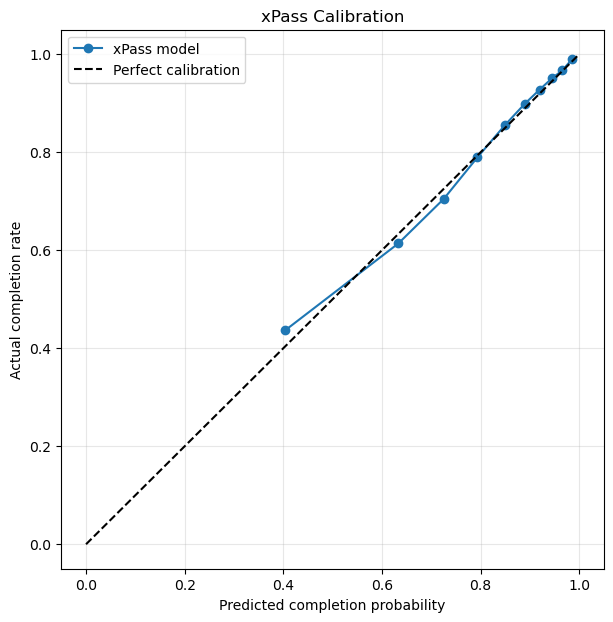

,mean_predicted,actual_completion,pass_count,difference
probability_bin,,,,
"(0.028399999999999998, 0.559]",0.403478,0.436315,34074,0.032837
"(0.559, 0.687]",0.633150,0.613770,34073,-0.019380
"(0.687, 0.761]",0.725402,0.704898,34073,-0.020504
"(0.761, 0.824]",0.793611,0.789599,34073,-0.004012
"(0.824, 0.872]",0.849652,0.855696,34074,0.006045
"(0.872, 0.906]",0.889883,0.899187,34073,0.009304
"(0.906, 0.933]",0.919852,0.927919,34073,0.008067
"(0.933, 0.956]",0.944735,0.950929,34073,0.006194
"(0.956, 0.975]",0.965636,0.966924,34073,0.001288


In [49]:
# -------------------------------------------
# 6. Check Calibration
# -------------------------------------------

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    LR_proba,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(prob_pred, prob_true, marker="o", label="xPass model")
ax.plot([0, 1], [0, 1], linestyle="--", color="black", label="Perfect calibration")

ax.set_xlabel("Predicted completion probability")
ax.set_ylabel("Actual completion rate")
ax.set_title("xPass Calibration")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

calibration_df = pd.DataFrame({
    "predicted": LR_proba,
    "actual": y_test.values
})

calibration_df["probability_bin"] = pd.qcut(
    calibration_df["predicted"],
    q=10,
    duplicates="drop"
)

calibration_summary = calibration_df.groupby(
    "probability_bin",
    observed=True
).agg(
    mean_predicted=("predicted", "mean"),
    actual_completion=("actual", "mean"),
    pass_count=("actual", "size")
)

calibration_summary["difference"] = (
    calibration_summary["actual_completion"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary)

- A basic way to measure the trustworthiness of the predictions - how closely to predicted probabilities match reality
- Above the line: model is underconfident
- Below the line: model is overconfident

### Gradient Boosting
- Another model used for classification
- Continous numerical inputs (independent variables/ features) - e.g. pass coordinates, pass length, etc...
- Produces a probability of a certain outcome (dependant variable) - i.e if the probability the pass is successful

- It works by combining decision trees to identify patterns
- e.g. if pass length is greater than 15m the probability of success decreases.
- Then after that a new tree, e.g. if the pass was headed the probability of success decreases.
- It uses something called a loss function to determine how subsequent trees should ajust the exisiting prediciton.
- All tress combine to produces a final probability of pass success.
- Then we can classify the outcome of the pass again $p > 0.5$ is successful.

Gradient boosting captures the non-linear relationships between variables and pass completion.

In [26]:
# -------------------------------------------
# 7. Train a Gradient Boosting model
# -------------------------------------------
from sklearn.ensemble import HistGradientBoostingClassifier

GB_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)

GB_model.fit(X_train, y_train)

GB_proba = GB_model.predict_proba(X_test)[:, 1]
GB_pred = (GB_proba >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, GB_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, GB_proba):.4f}")
print(f"Log Loss:  {log_loss(y_test, GB_proba):.4f}")
print(f"Brier:     {brier_score_loss(y_test, GB_proba):.4f}")

Accuracy:  0.8848
ROC-AUC:   0.9115
Log Loss:  0.2747
Brier:     0.0840


In [46]:
# -------------------------------------------
# 8. Evaluate feature importance
# -------------------------------------------

from sklearn.inspection import permutation_importance

gb_importance = permutation_importance(
    GB_model,
    X_test,
    y_test,
    scoring="neg_log_loss",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": gb_importance.importances_mean,
    "std": gb_importance.importances_std
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

display(importance_df)

,feature,importance,std
6,pass_angle_cos,0.109752,0.000509
2,end_x,0.100062,0.000327
4,pass_length,0.097288,0.000233
3,end_y,0.079800,0.000941
1,y,0.010728,0.000090
5,pass_angle_sin,0.010607,0.000128
0,x,0.002894,0.000071


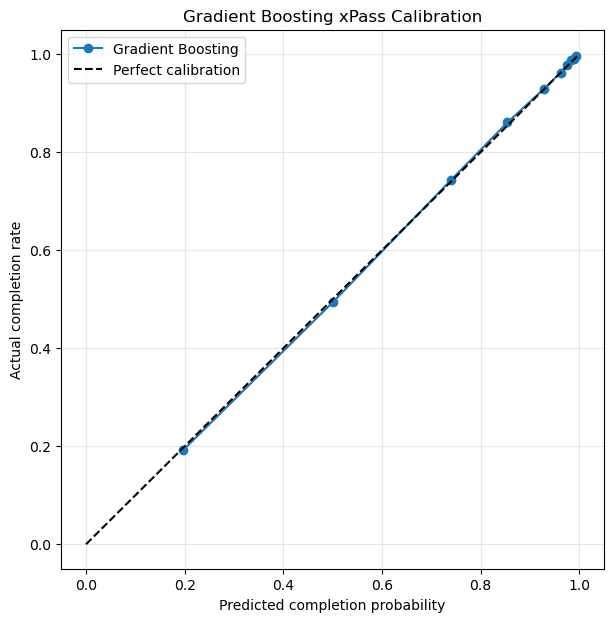

,mean_predicted,actual_completion,pass_count,difference
probability_bin,,,,
"(-0.000554, 0.33]",0.196398,0.191524,34074,-0.004873
"(0.33, 0.661]",0.500846,0.494409,34073,-0.006437
"(0.661, 0.804]",0.740587,0.743873,34073,0.003286
"(0.804, 0.9]",0.854412,0.860799,34073,0.006387
"(0.9, 0.95]",0.928697,0.929653,34074,0.000956
"(0.95, 0.971]",0.962045,0.962346,34073,0.000300
"(0.971, 0.98]",0.975785,0.978135,34073,0.002350
"(0.98, 0.986]",0.983552,0.987380,34073,0.003828
"(0.986, 0.991]",0.988734,0.990931,34073,0.002197


In [28]:
# -------------------------------------------
# 9. Check Calibration
# -------------------------------------------

prob_true, prob_pred = calibration_curve(
    y_test,
    GB_proba,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Gradient Boosting"
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    label="Perfect calibration"
)

ax.set_xlabel("Predicted completion probability")
ax.set_ylabel("Actual completion rate")
ax.set_title("Gradient Boosting xPass Calibration")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

calibration_gb_df = pd.DataFrame({
    "predicted": GB_proba,
    "actual": y_test.values
})

calibration_gb_df["probability_bin"] = pd.qcut(
    calibration_gb_df["predicted"],
    q=10,
    duplicates="drop"
)

calibration_summary = calibration_gb_df.groupby(
    "probability_bin",
    observed=True
).agg(
    mean_predicted=("predicted", "mean"),
    actual_completion=("actual", "mean"),
    pass_count=("actual", "size")
)

calibration_summary["difference"] = (
    calibration_summary["actual_completion"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary)

### Evaluation

| Metric | Logistic Regressor | Gradient Booster |
|:---|---:|---:|
| Accuracy | 82.90% | **88.48%** |
| ROC-AUC | 0.8054 | **0.9115** |
| Log Loss | 0.3846 | **0.2747** |
| Brier Score | 0.1215 | **0.0840** |

- **Accuracy**: Measures the proportion of passes that the model correctly classifies as either successful or unsuccessful, assuming P > 0.5 is classified as successful. The baseline model, which predicts every pass as successful, produced an accuracy of 81.34%. So the Logistic Regressor only provided a small improvement upon this at 82.90%, while the Gradient Booster was significantly more accurate at 88.48%.
- **ROC-AUC**: A good model should assign higher probabilities to successful passes and lower probabilities to unsuccessful passes, ROC-AUC measures how effectively the model does this. A ROC-AUC value of 0.5 would represent a model no better then randomly assigining pass success. A value closer to 1 is better. So the Gradient Booster's value of 0.9115, suggests that if one unssuccessful and one successful pass were chosen at random, the model has a 91.15% probability of assigning the successful pass a higher xPass probability. This is a significant better result than the logisitc regressor at 0.8054.
- **Log Loss**: Measures how accurate the predicted xPass probabilities are, heavily peanlising confidently incorrect predictions. A Log loss of 0 would indicate perfect predictions. So once again, the Gradient Booster out performs the logisitc regressor by 28.6%.
- **Brier Score**: Measures the mean squared difference between the predicted probabilities and the actual outcome, once again heavily penalising confidently incorrect predictions. A value of 0 indicates perfect predicitons, while a value of 0.25 is equivalent of predicting 50% for every pass. Once again the gradient booster outperforms the logistic regressor by 30.9%. 